AIMS 5702 Artificial Intelligence in Practice (Fall 2026-27)

**AIMS 5702 Assignment 4**

**Assessment scope:** Problems A.1, A.2, A.3 and C are required. Problem A.4 and all of Problems B and D are optional, ungraded extensions. These extensions carry no marks or bonus credit and are not required for full credit. No submission of work from Problems A.4, B or D is required.

**Mark allocation:** 10 marks in total: 8 marks for the coding tasks and 2 marks for the in-class Q&A.

| Question | Marks |
| --- | --- |
| A.1. Patch embedding | 1.5 |
| A.2. Positional encoding | 1.5 |
| A.3. ViT classifier | 2 |
| A.4. Run training | Optional (not graded) |
| **Problem A total** | **5** |
| B.1. ONNX inference | Optional (not graded) |
| B.2. ONNX on a web page | Optional (not graded) |
| C. Multi-head attention | 3 |
| D.1. Text dataset preparation | Optional (not graded) |
| D.2. Text model creation | Optional (not graded) |
| D.3. Text training | Optional (not graded) |
| **Coding subtotal (A.1–A.3 + C)** | **8** |
| In-class Q&A | 2 |
| **Total** | **10** |

Please complete the required parts of this colab and:

* Download it as **both** .ipynb file and .pdf file (click on file -> download -> download as .ipynb file)
* Submit **both** .pdf and .ipynb file to blackboard

**Accelerator:** Training can run on CPU, but a GPU is much faster. We recommend a T4 GPU.

**In-class lab:** Lecture hour at ELB LT1.

**Deadline of submission:** 5th November, 2026 (Thursday), as it is an in-class lab

First, let us import all necessary libraries for this one

In [1]:
import cv2
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal
import math
import time
from typing import List, Union, Dict
import scipy
import scipy.special

Same utility function for training

We will save the trained model to Google Drive. Enter a folder path relative to My Drive below. Colab will ask for permission to access your Google Drive; the code creates the folder if it does not exist.


In [2]:
#@title Mount Google drive (you need to grant colab to access your Google Drive)

from google.colab import drive

drive.mount('/content/drive')

srcpath = 'cuhk_courses/aims5702/tmp'  #@param {type:"string"}
srcpath = os.path.join('/content/drive/My Drive', srcpath)
os.makedirs(srcpath, exist_ok=True)


Mounted at /content/drive


In this one, we will build transformer, for both image classification and text processing. Note that GPU training is highly suggested, as it is much faster than CPU training.

First, let us use the FashionMNIST dataset.


# Problem A. Transformer on FashionMNIST — 5 marks


Again, let us load the dataset.

In [3]:
#@title Load the training dataset

# Define transformations for the training and test sets

mean_train = 0.2860405743122101
std_train = 0.3530242443084717
transform_train = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((mean_train,), (std_train,))
])

# The transformation applied to the testing is the same as training
transform_test = transforms.Compose([
    # For the ease of network design, we resize the image to 32x32.
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((mean_train,), (std_train,))
])

# Load the FashionMNIST dataset
train_dataset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform_train
)

test_dataset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform_test
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 195kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.69MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.0MB/s]


## Transformer Model functions

Although, we can build a transformer on raw pixels, that is often slow in training. Instead, let us first downsample the input image into small size through a lightweight CNN.

## Problem A.1. Patch embedding — 1.5 marks

Given an input image with resolution of `1(channel)x32(height)x32(width)`, design a one-layer network to convert that into `768(embedding_dim)x8(height)x8(width)`. It basically downsamples the input images by 4x. Then flatten it into a `768(embedding_dim)x64(num_patches)`

**Hint:**
* You can achieve this through a stride=4 and kernel=4 convolution.
* You can use `torch.flatten(x, start_dim, end_dim)` to flatten 2D image into 1D sequence.
* Return `[batch_size, embedding_dim, num_patches]` from `PatchEmbedding`. The provided `ViTClassifier.forward` transposes this to `[batch_size, num_patches, embedding_dim]`; do not transpose it a second time inside `PatchEmbedding`.

In [4]:
#@title Problem A.1. Patch embedding class — 1.5 marks

def power_base_10000(x):
  """
  Computes the power of 10000.0 to the input tensor.

  Args:
    x: The input tensor.
  """
  return torch.exp(math.log(10000.0) * x)

class PatchEmbedding(nn.Module):
  """
  A module to convert an image into a sequence of patches and embed them.
  This is the first layer of a Vision Transformer.
  """
  def __init__(self, img_size, patch_size=4, in_channels=1, embedding_dim=768):
    """
    Args:
      img_size: The size of the image.
      patch_size: The size of the patch.
      in_channels: The number of channels in the image.
      embedding_dim: The dimension of the embedding.
    """
    super().__init__()
    #####################
    # Your code goes here
    #####################
    self.projection = nn.Conv2d(
        in_channels, embedding_dim,
        kernel_size=patch_size, stride=patch_size
    )


  def forward(self, x):
    """
    Args:
      x: The input tensor with shape (Batch_Size, In_Channels, Height, Width).

    Returns:
      The output tensor with shape (Batch_Size, Embedding_Dim, Number_of_Patches).
    """
    #####################
    # Your code goes here
    #####################
    x = self.projection(x)
    return torch.flatten(x, start_dim=2)

## Problem A.2. Positional encoding — 1.5 marks

Let us define the positional encoding.

We can precompute a table where `position_encoding_table[t, j]` contains the encoding at token position `t` and feature index `j`. Follow the frequency convention in the course formula below. Token positions start at `t = 0`; the displayed pairs are indexed by `k = 1, ..., embedding_dim / 2`, corresponding to Python columns `2 * (k - 1)` (sine) and `2 * (k - 1) + 1` (cosine).


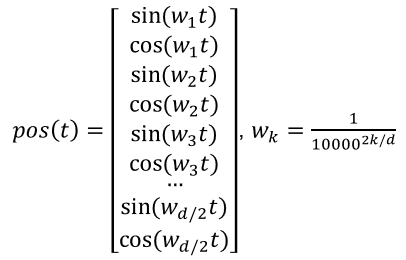

In [5]:
#@title Problem A.2. PositionalEncoding — 1.5 marks

class PositionalEncoding(nn.Module):
  """
  Adds positional information to the patch embeddings.
  """
  def __init__(self, embedding_dim, max_seq_length=512):
    """
    Args:
      embedding_dim: The dimension of the embedding.
      max_seq_length: The maximum sequence length.
    """
    super().__init__()
    position_encoding_table = torch.zeros(max_seq_length, embedding_dim)
    # Create a position table.
    # position_encoding_table[i, :] should be length embedding_dim vector that
    # encodes the position i.
    #####################
    # Your code goes here
    #####################
    self.register_buffer('position_encoding_table', position_encoding_table)
    positions = torch.arange(max_seq_length, dtype=torch.float32).unsqueeze(1)
    k = torch.arange(1, embedding_dim // 2 + 1, dtype=torch.float32)
    frequencies = power_base_10000(-2 * k / embedding_dim)
    angles = positions * frequencies

    position_encoding_table[:, 0::2] = torch.sin(angles)
    position_encoding_table[:, 1::2] = torch.cos(angles)

  def forward(self, x):
    """
    Args:
      x: The input tensor with shape
          (Batch_Size, Sequence_Length, Embedding_Dim).

    Returns:
      The output tensor with shape (Batch_Size, Sequence_Length, Embedding_Dim).
    """
    _, seq_length, _ = x.shape
    return x + self.position_encoding_table[np.newaxis, :seq_length, :]

In [6]:
#@title Problem A.3. ViTClassifier — 2 marks

# Transformer class
class ViTClassifier(nn.Module):
  """
  Complete Vision Transformer model for classification.
  """
  def __init__(self, img_size=32, patch_size=4, in_channels=1, num_classes=10,
               embedding_dim=768, num_heads=12, num_layers=6, dropout_rate=0.1):
    super().__init__()

    # First, let us create the patch embedding and positional encoding layers.
    self.patch_embedding = PatchEmbedding(
        img_size, patch_size, in_channels, embedding_dim
    )
    self.positional_encoding = PositionalEncoding(
        embedding_dim, (img_size // patch_size)**2
    )

    # Transformer Encoder layers
    encoder_layer = nn.TransformerEncoderLayer(
        d_model=embedding_dim,
        nhead=num_heads,
        dropout=dropout_rate,
        batch_first=True
    )
    self.transformer_encoder = nn.TransformerEncoder(
        encoder_layer, num_layers=num_layers
    )

    # This is the classification token CLS.
    self.cls_token = nn.Parameter(torch.randn(1, 1, embedding_dim))

    # This is the MLP head for classification.
    self.mlp_head = nn.Sequential(
        nn.LayerNorm(embedding_dim),
        nn.Linear(embedding_dim, num_classes)
    )

  def forward(self, x):
    """
    Args:
      x: The input tensor with shape (Batch_Size, In_Channels, Height, Width).

    Returns:
      The output tensor with shape (Batch_Size, Num_Classes).
    """
    # 1. Convert image to patches
    # (Batch_Size, In_Channels, Height, Width) ->
    #     (Batch_Size, H_p * W_p, Embedding_Dim)
    # H_p = Height // Patch_Size
    # W_p = Width // Patch_Size
    batch_size, _, _, _ = x.shape
    patches_embedded = self.patch_embedding(x).transpose(1, 2)

    # 2. Add positional information
    # (Batch_Size, H_p * W_p, Embedding_Dim) ->
    #     (Batch_Size, H_p * W_p, Embedding_Dim)
    patches_with_pos = self.positional_encoding(patches_embedded)

    # 3. Concatenate the learnable CLS token
    # After concatenating, the shape of the input tokens should be
    # (Batch_Size, H_p * W_p + 1, Embedding_Dim)
    #####################
    # Your code goes here
    #####################
    cls_tokens = self.cls_token.expand(batch_size, -1, -1)
    input_tokens_extended = torch.cat(
        [cls_tokens, patches_with_pos], dim=1
    )

    # 4. Pass through the Transformer Encoder
    output_tokens = self.transformer_encoder(input_tokens_extended)

    # 5. Pass the CLS token through the MLP head for final classification
    #####################
    # Your code goes here
    #####################
    cls_token = output_tokens[:, 0, :]
    output = self.mlp_head(cls_token)

    return output

## Problem A.4. Run training — Optional (not graded)

**Optional extension — not graded.** Training, the accuracy target and saving the trained model in this section carry no marks or bonus credit and are not required for full credit. You may skip A.4 and the optional Problem B and continue to Problem C.

Similar, let us use GPU this time.

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


At last, uses the same training and testing loop.

At last, defines the dataloader, model, and optimizer.

In [8]:
#@title Dataloader, model, and optimizer

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

model = ViTClassifier()
model.to(device)
loss_fn = nn.CrossEntropyLoss()

epochs = 1   # Number of training epochs
optimizer = torch.optim.Adam(
  model.parameters(),    # All trainable parameters.
  lr=1e-4                # Learning rate
)

In [9]:
#@title Utility functions for training

def train_one_epoch(
    dataloader: torch.utils.data.DataLoader,
    model: nn.Module,
    loss_fn: nn.Module,
    optimizer: optim.Optimizer,
    device: str='cpu',
    loss_print_iter: int=100
  ):
  num_train_samples = len(dataloader.dataset)

  # Set the model to training mode
  model.train()
  all_losses = []
  all_acc = []

  for batch_index, (image, label) in enumerate(dataloader):
    image, label = image.to(device), label.to(device)
    pred = model(image)
    loss = loss_fn(pred, label)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

    # Calculate the loss
    all_losses.append(loss.item())
    acc = ((pred.argmax(1) == label).type(torch.float).sum().item() /
           image.shape[0])
    all_acc.append(acc)

    if batch_index % loss_print_iter == 0:
      loss, trained_samples = loss.item(), (batch_index + 1) * image.shape[0]
      print(f'loss: {loss:>7f} '
            f'[{trained_samples:>5d}/{num_train_samples:>5d}] ')

  return all_losses, all_acc

def test_all_samples(
    dataloader: torch.utils.data.DataLoader,
    model: nn.Module,
    loss_fn: nn.Module,
    device: str='cpu'
) -> tuple[float, float]:
  model.eval()  # Set the model to evaluation mode
  num_testing_samples = len(dataloader.dataset)
  num_batches = len(dataloader)
  test_loss, correct = 0, 0

  # Disable gradient calculation for inference
  with torch.no_grad():
    for image, label in dataloader:
      image, label = image.to(device), label.to(device)
      pred = model(image)
      test_loss += loss_fn(pred, label).item()
      correct += (pred.argmax(1) == label).type(torch.float).sum().item()

  test_loss /= num_batches
  acc = correct / num_testing_samples
  print(f'Test Error: \n Accuracy: {(100*acc):>0.1f}%, '
        f'Avg loss: {test_loss:>8f} \n')
  return test_loss, acc

At last, let us try to train it.

If your model is defined correctly, you should get accuracy larger than 70%.

The training may take about 5-10 min on GPU. You can train more epochs for higher accuracy.


In [10]:
#@title Training

for t in range(epochs):
  print(f"Epoch {t+1}\n-------------------------------")
  start_time =time.time()
  _, _ = train_one_epoch(train_loader, model, loss_fn, optimizer, device=device)
  print(f'One epoch takes {time.time() - start_time}')
  _, _ = test_all_samples(test_loader, model, loss_fn, device=device)

test_all_samples(test_loader, model, loss_fn, device=device)

print("Training done!")

Epoch 1
-------------------------------
loss: 2.406013 [   32/60000] 
loss: 1.019125 [ 3232/60000] 
loss: 1.021541 [ 6432/60000] 
loss: 0.573272 [ 9632/60000] 
loss: 0.503649 [12832/60000] 
loss: 0.641947 [16032/60000] 
loss: 0.822045 [19232/60000] 
loss: 0.837451 [22432/60000] 
loss: 0.873580 [25632/60000] 
loss: 0.887981 [28832/60000] 
loss: 0.634274 [32032/60000] 
loss: 1.139926 [35232/60000] 
loss: 0.312295 [38432/60000] 
loss: 0.470984 [41632/60000] 
loss: 0.509591 [44832/60000] 
loss: 0.326936 [48032/60000] 
loss: 0.340670 [51232/60000] 
loss: 0.455199 [54432/60000] 
loss: 0.332050 [57632/60000] 
One epoch takes 310.1386332511902
Test Error: 
 Accuracy: 82.8%, Avg loss: 0.485041 

Test Error: 
 Accuracy: 82.8%, Avg loss: 0.485041 

Training done!


**Important:** Run the code below to save the trained model to Google Drive. The optional Problem B uses this checkpoint, so you do not need to repeat the training run.


In [13]:
#@title Save model to the disk

MODEL_PATH = os.path.join(srcpath, 'trained_model_fashionmnist.pth')
torch.save(model.state_dict(), MODEL_PATH)

# Problem B. Save the trained model as ONNX and run inference — Optional (not graded)

**Optional extension — not graded.** This entire part, including B.1 and B.2, carries no marks or bonus credit and is not required for full credit. You may skip it and continue to Problem C. No submission for this part is required.


First, load the saved model

In [14]:
model = ViTClassifier()
model.load_state_dict(torch.load(MODEL_PATH, map_location="cpu", weights_only=True))
model.cpu().eval()


ViTClassifier(
  (patch_embedding): PatchEmbedding(
    (projection): Conv2d(1, 768, kernel_size=(4, 4), stride=(4, 4))
  )
  (positional_encoding): PositionalEncoding()
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (linear1): Linear(in_features=768, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=768, bias=True)
        (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (mlp_head): Sequential(
    (0): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_fea

In next step, let us define the output path

In [15]:
ONNX_PATH = os.path.join(srcpath, 'fashionmnist.onnx')

At last, we need to install ONNX.

In [16]:
!pip install onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 33.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 77.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [onnx]


In [17]:
import onnx
import onnxruntime

## Export the model to ONNX — Optional (not graded)


Run the provided code to export the trained model. The dummy input must have shape `[1, 1, 32, 32]`. The batch dimension remains dynamic.


In [18]:
# We first need to define a dummy input. The value does not matter. Just make
# sure the tensor shape is correct.
model.cpu().eval()
dummy_input = torch.zeros((1, 1, 32, 32))

# Define names for the input and output nodes
input_names = ['input']
output_names = ['output']

# Define axes that should have dynamic (variable) dimensions
# This allows the ONNX model to handle different batch sizes at runtime.
dynamic_axes = {
    'input': {0: 'batch_size'},   # Make the 0th dimension (batch size) dynamic
    'output': {0: 'batch_size'}  # Make the 0th dimension (batch size) dynamic
}

torch.onnx.export(
    model,              # The PyTorch model to export
    dummy_input,        # The sample input tensor
    ONNX_PATH,          # Where to save the model (file or file-like object)
    dynamo=False,      # Use the exporter that supports the existing dynamic_axes setup.
    export_params=True, # Export trained weights with the model
    opset_version=17,   # The ONNX version to export to (choose one supported by your target platform)
    do_constant_folding=True, # Whether to execute constant folding for optimization
    input_names=input_names,  # Names of the model's inputs
    output_names=output_names, # Names of the model's outputs
    dynamic_axes=dynamic_axes # Specify dynamic dimensions
)

print(f"Model successfully exported to {ONNX_PATH}")

/tmp/ipykernel_5770/1988959279.py:17: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Model successfully exported to /content/drive/My Drive/cuhk_courses/aims5702/tmp/fashionmnist.onnx


## Problem B.1. Reload the trained model and test it — Optional (not graded)


Let us first reload model and check if it is correct.

In [19]:
onnx_model = onnx.load(ONNX_PATH)
# This raises an exception if the model is invalid
onnx.checker.check_model(onnx_model)
print("ONNX model is well-formed.")

ort_session = onnxruntime.InferenceSession(
    ONNX_PATH, providers=["CPUExecutionProvider"]
)


ONNX model is well-formed.


In [20]:
#####################
# You need to change this block
#####################

from PIL import Image

def predict_onnx(raw_image):
  image = transform_test(Image.fromarray(raw_image))
  inputs = image.unsqueeze(0).numpy().astype(np.float32)
  outputs = ort_session.run(['output'], {'input': inputs})[0]
  return int(outputs.argmax(axis=1)[0])


Now test the model on the first 9 samples in the test set.


In [21]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Let us use the first 9 samples as testing cases.

To mimic a deployment platform, the provided block loads raw images without transformations. In your prediction code, apply the same preprocessing as in Problem A before passing each image to ONNX Runtime.

Do not change the block below.

In [22]:
raw_test_dataset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
)
testing_images = []
gt_labels = []
for i, (image, label) in enumerate(raw_test_dataset):
  testing_images.append(np.asarray(image))
  gt_labels.append(class_names[label])
  if i == 8:
    break

Use your prediction function to classify all 9 images in `testing_images`. Convert each predicted class index to a name using `class_names`, and append the names to `est_labels` in the same order as `gt_labels`.

The provided plotting code compares predictions with ground truth. As in the original exercise, at least half of these predictions are expected to be correct.


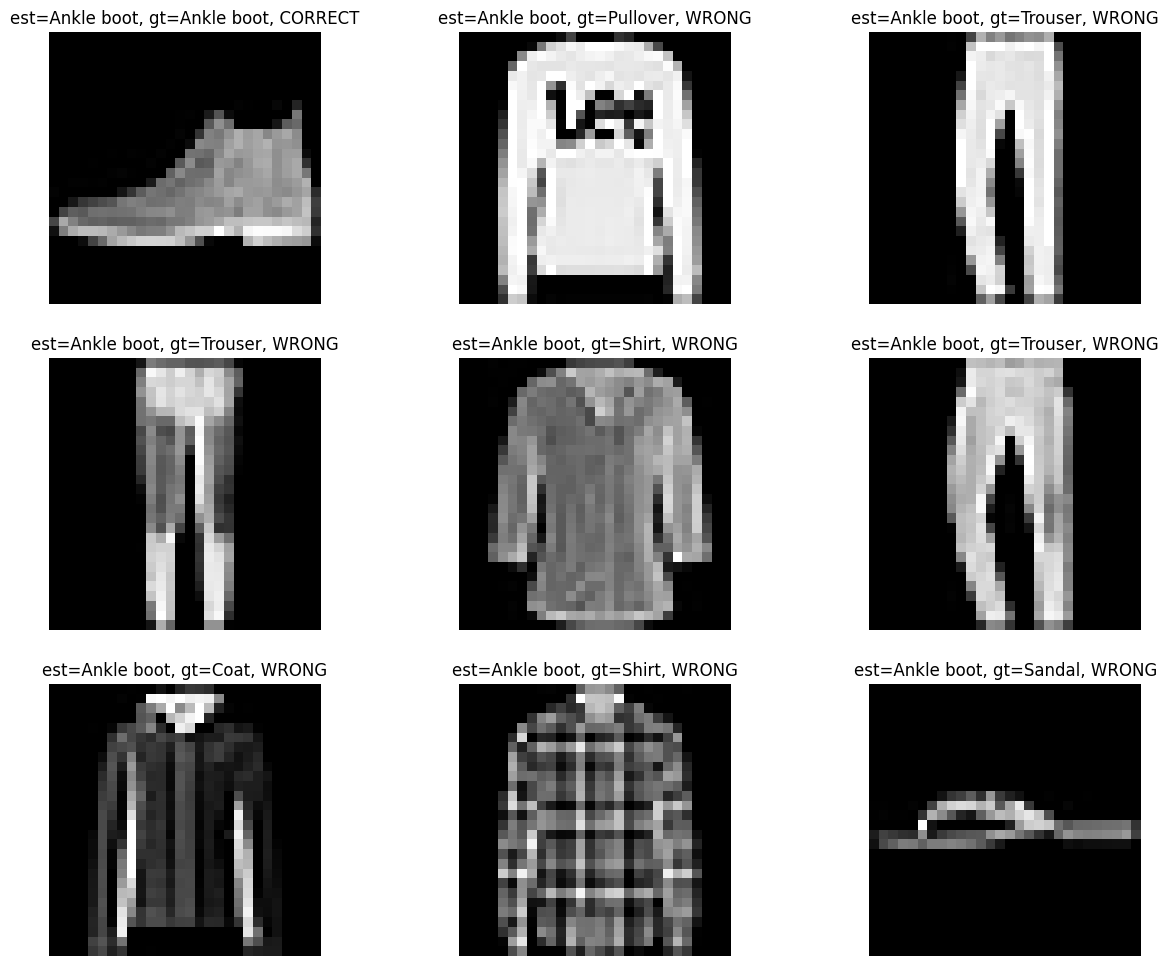

In [23]:
est_labels = []
#####################
# Your code goes here: fill est_labels with 9 predicted class names.
#####################
for image in testing_images:
  label = predict_onnx(image)
  est_labels.append(class_names[label])

plt.figure(figsize=(15, 12))
for i in range(len(testing_images)):
  correct = 'CORRECT' if est_labels[i] == gt_labels[i] else 'WRONG'
  plt.subplot(3, 3, i + 1)
  plt.imshow(testing_images[i], cmap='gray')
  plt.axis('off')
  plt.title(f'est={est_labels[i]}, gt={gt_labels[i]}, {correct}')

## Problem B.2. Run ONNX on a web page — Optional (not graded)


Try to build an HTML page that runs the ONNX model. This can be time consuming; attempt it only if you are comfortable with web development.

This activity carries no marks or bonus credit. Submission is not required. If you choose to share your optional work, you may include:
* A screen record of how you run it.
* A zip file of webpage folder.

FYI, you can refer to some of these implementations:

https://github.com/mxkrn/onnxruntime-web-tutorial/tree/main

https://github.com/microsoft/onnxruntime-nextjs-template

https://onnxruntime.ai/docs/tutorials/web/classify-images-nextjs-github-template.html



# Problem C. Implement multi-head attention by yourself — 3 marks


Implement multi-head attention and compare its output with the PyTorch implementation.


Here we provided a reference implementation of softmax.

In [25]:
def softmax(x: np.ndarray) -> np.ndarray:
    e_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return e_x / np.sum(e_x, axis=-1, keepdims=True)

PyTorch uses two projection weight matrices in this simplified setting:
* The input projection matrix (`in_proj_weight`) stacks the Q, K and V projection weights in that order. We provide the three separate matrices `wq`, `wk` and `wv`, each with shape `[embedding_dim, embedding_dim]`.
* The output projection matrix (`out_proj.weight`), also with shape `[embedding_dim, embedding_dim]`, is applied after the heads are combined. The resulting tensor has shape `[batch_size, query_length, embedding_dim]`.

For a linear projection, `out_feat[j] = sum_i(in_feat[i] * weight[j, i])`: the first weight dimension indexes output features and the second indexes input features.


Also, here is how pytorch deal with multi-head attention
* For multi-head attention, it will split the result after input project into `num_head` independent tensors, and combined them on channel dimension after attentions.
* For example, if the K tensor before splitting is `1 x 32 x 128`, where batch size is 1, sequence length is 32, and embedding dimension is 128. Then, to create 4 heads (`num_head=4`), it will split this matrix into 4 `1 x 32 x 32` K tensors. Q and V are split in the same way. After attention, it will obtained 4 `1 x 32 x 32` output tensors. They will be combined into a single `1 x 32 x 128` tensor.
* For your reference, we provided `_split_heads` and `_combine_heads` for these two operations, although you can implement your own one.

For this exercise, consider the simplified case with no projection biases, no attention mask and no attention dropout. The supplied reference layer uses these settings.


In [26]:
#@title Problem C. CustomizedMultiHeadAttention — 3 marks

class CustomizedMultiHeadAttention(object):

  def __init__(self, embedding_dim: int, num_heads: int, dropout: float = 0.1):
    self.embedding_dim = embedding_dim
    self.num_heads = num_heads
    self.dim_each_head = embedding_dim // num_heads

  def set_params(self,
    param_dict: Dict[str, np.ndarray]
  ) -> None:
    """
    Set the parameters of the layer, like weight and bias of linear layer.

    Args:
      wq: The weight matrix for Q.
      wk: The weight matrix for K.
      wv: The weight matrix for V.
      wout: The weight matrix for the output.
    """
    self.wq = param_dict['wq']
    self.wk = param_dict['wk']
    self.wv = param_dict['wv']
    self.wout = param_dict['wout']

  def _split_heads(self, x: np.ndarray) -> np.ndarray:
    """
    Splits KQV matrix into multiple heads.

    Args:
      x: A tensor of shape (batch_size, sequence_length, embedding_dim)

    Returns:
      A tensor of shape (batch_size, num_heads, sequence_length, dim_each_head)
    """
    batch_size, seq_len, _ = x.shape
    x = x.reshape(batch_size, seq_len,
                  self.num_heads, self.dim_each_head).transpose(0, 2, 1, 3)
    return x

  def _combine_heads(self, x: np.ndarray) -> np.ndarray:
    """
    Combines multiple heads into a single matrix.

    Args:
      x: A tensor of shape
          (batch_size, num_heads, sequence_length, dim_each_head)

    Returns:
      A tensor of shape (batch_size, sequence_length, embedding_dim)
    """
    batch_size, _, seq_len, _ = x.shape
    x = x.transpose((0, 2, 1, 3))
    return x.reshape(batch_size, seq_len, self.embedding_dim)

  def forward(self, input_k: np.ndarray, input_v: np.ndarray, input_q: np.ndarray) -> np.ndarray:
    """
    Forward pass of the layer.

    Args:
      input_k: A tensor of shape (batch_size, kv_length, feature_dim)
      input_v: A tensor of shape (batch_size, kv_length, feature_dim)
      input_q: A tensor of shape (batch_size, q_length, feature_dim)

    Returns:
      The output of the layer, shape is (batch_size, q_length, embedding_dim).
    """
    #####################
    # Your code goes here
    #####################
    q = self._split_heads(input_q @ self.wq.T)
    k = self._split_heads(input_k @ self.wk.T)
    v = self._split_heads(input_v @ self.wv.T)

    scores = np.einsum('bhqd,bhkd->bhqk', q, k)
    scores = scores / math.sqrt(self.dim_each_head)
    attention = softmax(scores)

    output_heads = attention @ v
    combined = self._combine_heads(output_heads)
    return combined @ self.wout.T

Verify your implementation using the following code. Do not change the verification code or its test settings.


In [27]:
#@title Verification function

def verify_output(
    actual: Union[np.ndarray, List[np.ndarray]],
    reference: Union[np.ndarray, List[np.ndarray]],
    name: Union[str, List[str]],
    atol: float = 1e-6,
    rtol: float = 1e-6
) -> bool:
  """Return whether outputs have matching shapes and values within tolerance."""
  if isinstance(actual, np.ndarray):
    close = (isinstance(reference, np.ndarray)
             and actual.shape == reference.shape
             and np.allclose(actual, reference, atol=atol, rtol=rtol))
    if close:
      print(f"{name} is close to the reference output.")
    else:
      print(f"{name} is not close to the reference output.")
    return bool(close)
  if isinstance(actual, list) and isinstance(reference, list):
    if len(actual) != len(reference):
      print(f"{name}: output list lengths do not match.")
      return False
    if isinstance(name, list) and len(name) != len(actual):
      raise ValueError("Provide one name for each output.")
    results = [
        verify_output(a, b, name[i] if isinstance(name, list) else f"{name}[{i}]",
                      atol=atol, rtol=rtol)
        for i, (a, b) in enumerate(zip(actual, reference))
    ]
    return all(results)
  print(f"{name}: expected NumPy output arrays; check the implementation.")
  return False

def compare_with_actual_layer(
    official_multi_head_attention: nn.Module,
    customized_multi_head_attention: CustomizedMultiHeadAttention,
    input_k: np.ndarray,
    input_v: np.ndarray,
    input_q: np.ndarray,
    wq: np.ndarray,
    wk: np.ndarray,
    wv: np.ndarray,
    wout: np.ndarray,
    a_tol: float = 1e-6,
    r_tol: float = 1e-6,
) -> bool:
  """
  Compare forward of your customized layer with the official layer.

  Args:
    official_layer: The official layer.
    customized_layer: The customized layer.
    input_k: The input numpy array for K (batch_size, kv_length, feature_dim).
    input_v: The input numpy array for V (batch_size, kv_length, feature_dim).
    input_q: The input numpy array for Q (batch_size, q_length, feature_dim).
    wq: The input numpy array for WQ (feature_dim, feature_dim).
    wk: The input numpy array for WK (feature_dim, feature_dim).
    wv: The input numpy array for WV (feature_dim, feature_dim).
    wout: The input numpy array for WOUT (feature_dim, feature_dim).
    a_tol: The absolute tolerance.
    r_tol: The relative tolerance.

  Returns:
    True if the output of the customized layer is close to the output of
    the official layer, False otherwise.
  """
  success = True
  input_k_torch, input_v_torch, input_q_torch = (
      torch.tensor(input_k),
      torch.tensor(input_v),
      torch.tensor(input_q)
  )

  # Set parameters
  official_multi_head_attention.in_proj_weight.data.copy_(
    torch.tensor(np.concatenate([wq, wk, wv], axis=0))
  )
  official_multi_head_attention.out_proj.weight.data.copy_(
    torch.tensor(wout)
  )
  customized_multi_head_attention.set_params({
    'wq': wq,
    'wk': wk,
    'wv': wv,
    'wout': wout
  })

  # Run forward.
  output_customized_np = customized_multi_head_attention.forward(
    input_k, input_v, input_q
  )
  output_official_torch, _ = official_multi_head_attention(
      input_q_torch, input_k_torch, input_v_torch)
  output_official_np = output_official_torch.detach().numpy()

  # Check output
  success = verify_output(output_customized_np, output_official_np,
                          'Output', atol=a_tol, rtol=r_tol)
  return success

In [28]:
#@title Run verification

verification_results = []
for batch_size, feature_dim, num_heads, sequence_length in [
    (1, 16, 4, 7),
    (1, 128, 8, 7),
    (1, 16, 4, 243),
    (8, 16, 4, 7),
]:
  print(f'=== Testing with batch_size = {batch_size} '
        f'feature_dim = {feature_dim} '
        f'num_heads = {num_heads} ===')
  def _apply_norm(x):
    with torch.no_grad():
      norm = torch.nn.LayerNorm(feature_dim)
      x_torch = torch.tensor(x)
      normed_torch = norm(x_torch)
    return normed_torch.numpy()
  # Mimic layered norm when generating input
  input_k = _apply_norm(np.random.randn(
      batch_size, sequence_length, feature_dim).astype(np.float32))
  input_v = _apply_norm(np.random.randn(
      batch_size, sequence_length, feature_dim).astype(np.float32))
  input_q = _apply_norm(np.random.randn(
      batch_size, sequence_length, feature_dim).astype(np.float32))
  wq = np.random.randn(feature_dim, feature_dim).astype(np.float32)
  wk = np.random.randn(feature_dim, feature_dim).astype(np.float32)
  wv = np.random.randn(feature_dim, feature_dim).astype(np.float32)
  wout = np.random.randn(feature_dim, feature_dim).astype(np.float32)

  customized_attention = CustomizedMultiHeadAttention(
      feature_dim, num_heads)
  torch_attention = nn.MultiheadAttention(
      feature_dim, num_heads, batch_first=True, bias=False)

  passed = compare_with_actual_layer(
      torch_attention,
      customized_attention,
      input_k, input_v, input_q, wq, wk, wv, wout,
      a_tol=1e-4, r_tol=1e-4,
  )
  verification_results.append(passed)

print(f"Verification: {sum(verification_results)}/{len(verification_results)} cases passed.")


=== Testing with batch_size = 1 feature_dim = 16 num_heads = 4 ===
Output is close to the reference output.
=== Testing with batch_size = 1 feature_dim = 128 num_heads = 8 ===
Output is not close to the reference output.
=== Testing with batch_size = 1 feature_dim = 16 num_heads = 4 ===
Output is close to the reference output.
=== Testing with batch_size = 8 feature_dim = 16 num_heads = 4 ===
Output is close to the reference output.
Verification: 3/4 cases passed.


# Problem D. Transformer on text classification — Optional (not graded)

**Optional extension — not graded.** This entire part, including D.1–D.3, carries no marks or bonus credit and is not required for full credit. Dataset preparation, model implementation, training, and the accuracy target below are optional extension activities. No submission for this part is required. Only follow the environment setup below if you choose to attempt this extension.


This optional exercise uses the existing PyTorch environment from Problems A–C. Continue in the same session; no package installation, downgrade or runtime restart is needed. The supplied helper code uses the Python standard library to load IMDB and build its vocabulary.


In [31]:
#@title Environment setup
# No additional packages are required. Continue with the imports below.


The first run downloads the full IMDB dataset, preferring the [fast.ai mirror](https://s3.amazonaws.com/fast-ai-nlp/imdb.tgz), with the Stanford archive as a fallback. The helper preserves the original train/test split and reads either archive layout without installing any packages.

If downloads are blocked in your runtime, download `imdb.tgz` on your computer and upload it using the Colab Files panel. Keep its filename and do not extract it. The helper looks in the current directory and `./data` before accessing the network. An uploaded `aclImdb_v1.tar.gz` is also supported.


In [32]:
import os
import re
import math
import random
import time
import tarfile
import shutil
import urllib.request
from collections import Counter
from pathlib import Path, PurePosixPath

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np

from typing import List, Tuple
from torch.utils.data import Dataset, DataLoader

# Utility from Problem A, repeated so this section is self-contained.
def power_base_10000(x):
  return torch.exp(math.log(10000.0) * x)


First, define some constant

In [33]:
max_seq_length = 256  # Maximum token length
batch_size = 32
vocab_cap = 30000  # Size of vocabulary

## Problem description

The IMDB dataset contains several movie comments, and one label, whether this comment is positive or negative. We will train a transformer to check to predict this label (positive or negative) from the input comment.

To achieve this, the main different from Problem A is how to encode text. Here we use a simple encoder, which basically does follows:

* **Raw input**, which will be a sentence, like `This is a terrible movie`
* **Chop into tokens**. Here we chop it into a single word (token) and convert to lower cases, like `this` `is` `a` `terrible` `movie`. This is done through a simple tokenizer (5 tokens in this example).
* **Convert tokens to ID**. We further convert each token (word) into a ID (a number), so that it can be process by the network. This is done through a simple vocabulary (dictionary).
* **Compute the embedding feature of ID**. Since a single scalar is hard to be process by the network, we further encode them into a vector, using `nn.Embedding`.

The chop_into_token and convert_token_to_Id steps are done in the dataset creation, and embedding feature calculation is done in the first step of the network.

## Problem D.1. Build dataset (just run it) — Optional (not graded)


Load the labeled reviews from the [official IMDB dataset](https://ai.stanford.edu/~amaas/data/sentiment/index.html). Keep the original train/test split: 25,000 reviews in each, with equal numbers of positive and negative reviews. Unlabeled reviews are excluded.


In [34]:
#@title Load IMDB with a mirror and local-file fallback (no extra packages)

# The fast.ai mirror contains the full IMDB dataset, with the original splits.
# Source: https://github.com/fastai/fastai/blob/master/fastai/data/external.py
IMDB_SOURCES = [
    ('https://s3.amazonaws.com/fast-ai-nlp/imdb.tgz', 'imdb.tgz'),
    ('https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz',
     'aclImdb_v1.tar.gz'),
]
imdb_cache = Path('./data')
imdb_cache.mkdir(parents=True, exist_ok=True)


def load_imdb_reviews(archive_path):
  """Read labeled reviews directly from either supported IMDB archive.

  Keep the original train/test split and raw labels: 1 = negative, 2 = positive.
  Exclude unlabeled reviews and do not extract files onto disk.
  """
  splits = {'train': [], 'test': []}
  label_ids = {'neg': 1, 'pos': 2}
  with tarfile.open(archive_path, mode='r|gz') as archive:
    for member in archive:
      parts = PurePosixPath(member.name).parts
      if (not member.isfile() or len(parts) != 4
          or parts[0] not in ('aclImdb', 'imdb') or parts[1] not in splits
          or parts[2] not in label_ids or not parts[3].endswith('.txt')):
        continue
      with archive.extractfile(member) as review_file:
        text = review_file.read().decode('utf-8')
      splits[parts[1]].append((label_ids[parts[2]], text))

  for split, examples in splits.items():
    counts = Counter(label for label, _ in examples)
    if counts != {1: 12500, 2: 12500}:
      raise ValueError(f'Unexpected IMDB {split} split: {dict(counts)}')
  return splits['train'], splits['test']


def get_imdb_reviews():
  # Accept a cached archive or one uploaded through the Colab Files panel.
  local_candidates = [
      imdb_cache / 'imdb.tgz', imdb_cache / 'aclImdb_v1.tar.gz',
      Path('imdb.tgz'), Path('aclImdb_v1.tar.gz'),
  ]
  for archive_path in local_candidates:
    if archive_path.is_file():
      try:
        reviews = load_imdb_reviews(archive_path)
        print(f'Loaded IMDB from {archive_path}')
        return reviews
      except (OSError, EOFError, ValueError, tarfile.TarError) as error:
        print(f'Could not read {archive_path}: {error}')

  download_errors = []
  for url, filename in IMDB_SOURCES:
    archive_path = imdb_cache / filename
    partial_path = archive_path.with_suffix(archive_path.suffix + '.part')
    print(f'Downloading IMDB from {url}')
    try:
      request = urllib.request.Request(url, headers={'User-Agent': 'AIMS5702-notebook/1.0'})
      with urllib.request.urlopen(request, timeout=30) as response:
        with partial_path.open('wb') as output_file:
          shutil.copyfileobj(response, output_file)
      # Validate the complete archive before caching it as a successful download.
      reviews = load_imdb_reviews(partial_path)
      partial_path.replace(archive_path)
      print(f'IMDB cached at {archive_path}')
      return reviews
    except (OSError, EOFError, ValueError, tarfile.TarError) as error:
      partial_path.unlink(missing_ok=True)
      download_errors.append(f'{url}: {error}')
      print(f'Download failed: {error}. Trying the next source.')

  raise RuntimeError(
      'IMDB could not be downloaded from either source. '
      'Download imdb.tgz or aclImdb_v1.tar.gz on your computer, upload it '
      'through the Colab Files panel (without extracting or renaming it), '
      'then rerun this cell. The file can be in the current directory or ./data.\n'
      + '\n'.join(download_errors)
  )


raw_train_data, raw_test_data = get_imdb_reviews()
print(f'Number of training data is {len(raw_train_data)}')
print(f'Number of testing data is {len(raw_test_data)}')


IMDB cached at data/imdb.tgz
Number of training data is 25000
Number of testing data is 25000


And let us visualize how the data may look

In [35]:
for i, name in [(1, 'negative'), (2, 'positive')]:
  examples = [x for x in raw_train_data if x[0] == i]
  print(f'==== These are {name} feedbacks ====')
  for example in examples[::100][:5]:
    print(example)

==== These are negative feedbacks ====
(1, "I was bored, around 10pm, so I watched this movie. And I could not stop laughing. Everything was so ridiculous. The way the kids were acting like they were older than 11 just cracked me up. One of the kids had a ring, that supposedly killed people after 3 or so years. It gave me the impression that he wanted to be a gangster.<br /><br />It's pretty hard to take little kids seriously, especially when it has to do with eating worms. They act like everything is such a big deal, like if Billy (the main character) doesn't eat the worms then the world will end.<br /><br />This is a good movie for little kids (excluding the fact that a 5 year old says 'penis'), but not for teens or adults who don't want to waste their time.")
(1, 'This was allocated to the fans as the "winner takes all" match occurred between two separate "companies" (the World Wrestling Federation and the "Alliance": an amalgamation of former WCW and ECW superstars. Because the fin

First, let us define a simple tokenizer. Just chop the sentence into words and convert them to lower cases.

In [36]:
#@title A simple tokenizer

def simple_tokenize(text: str) -> List[str]:
  """For generalization, we just convert all letters to lower cases."""
  return re.findall(r"[A-Za-z0-9']+", text.lower())

And let us try it.

In [37]:
raw_str = 'This is a bad movie'
print(simple_tokenize(raw_str))

['this', 'is', 'a', 'bad', 'movie']


Here we also need to define some special tokens.
* PAD is used to pad the sentence when the input sentences is shorter than `max_seq_length`
* UNK is used when vocabulary cannot encode a new token.
* CLS is the CLS token as Problem A.

In [38]:
PAD, UNK, CLS = '<pad>', '<UNK>', '<cls>'

Build the vocabulary from the training reviews only. The supplied helper uses `collections.Counter` and a Python dictionary, with the same special-token IDs and vocabulary-size limit.


In [39]:
#@title Create vocabulary with Counter and a Python dictionary

class SimpleVocab(dict):
  """Map words to IDs; unknown words return UNK without changing the vocabulary."""
  def __init__(self, token_to_id):
    super().__init__(token_to_id)
    self.unk_id = token_to_id[UNK]

  def __missing__(self, token):
    return self.unk_id


def create_vocab(
    raw_data: List[Tuple[int, str]],
    vocab_cap: int = 30000
) -> SimpleVocab:
  """Build a vocabulary from training reviews only, including special tokens.

  Sort by descending frequency, then alphabetically to break ties.
  PAD, UNK and CLS keep IDs 0, 1 and 2, respectively.
  """
  specials = [PAD, UNK, CLS]
  if vocab_cap < len(specials):
    raise ValueError('vocab_cap must include all three special tokens.')
  counts = Counter()
  for _, text in raw_data:
    counts.update(simple_tokenize(text))
  for token in specials:
    counts.pop(token, None)
  ranked_tokens = sorted(counts, key=lambda token: (-counts[token], token))
  tokens = specials + ranked_tokens[:vocab_cap - len(specials)]
  return SimpleVocab({token: index for index, token in enumerate(tokens)})


simple_vocab = create_vocab(raw_train_data, vocab_cap=vocab_cap)


Let us try it with the simple tokenizer. Note the last token is unknown, so vocab output UNK (ID=1).

In [40]:
for word in [PAD, UNK, CLS]:
  print(f'special token `{word}` is encoded as {simple_vocab[word]}')

raw_str = 'This is a bad movie dafhancbahgdh'
for word in simple_tokenize(raw_str):
  print(f'word `{word}` is encoded as {simple_vocab[word]}')

special token `<pad>` is encoded as 0
special token `<UNK>` is encoded as 1
special token `<cls>` is encoded as 2
word `this` is encoded as 13
word `is` is encoded as 8
word `a` is encoded as 5
word `bad` is encoded as 77
word `movie` is encoded as 19
word `dafhancbahgdh` is encoded as 1


Then let us create a function that converts raw text into IDs, using the vocabulary above.

In [41]:
#@title Create dataset preprocessor.

class PadCollate:
  def __init__(self, max_len: int, pad_id: int, cls_id: int, vocab: any):
    self.max_len = max_len
    self.pad_id = pad_id
    self.cls_id = cls_id
    self.vocab = vocab

  def __call__(self, batch):
    """
    Args:
      batch: A list of tuples, each containing a list of tokens
            (tokenized movie comments) and a label (0 for negative or 1 for positive).

    Returns:
      A tuple containing the input ids, the key padding mask, and the labels.
    """
    # batch: List[(tokens, label)]
    ids_list, labels, lengths = [], [], []
    for toks, label in batch:
      ids = [self.vocab[token] for token in toks][: self.max_len - 1]
      ids = [self.cls_id] + ids
      ids_list.append(ids)
      labels.append(label)
      lengths.append(len(ids))

    T = min(self.max_len, max(lengths))
    B = len(batch)

    input_ids = torch.full((B, T), self.pad_id, dtype=torch.long)
    for i, ids in enumerate(ids_list):
      cur = ids[:T]
      input_ids[i, :len(cur)] = torch.tensor(cur, dtype=torch.long)

    # key_padding_mask: True is for padded token
    # (will be ignored by the Transformer encoder)
    # Shape is [batch_size, sequence_length], bool
    key_padding_mask = (input_ids == self.pad_id)

    # Also, packed the labels
    labels = torch.tensor(labels, dtype=torch.long)

    return input_ids, key_padding_mask, labels

pad_collate = PadCollate(
    max_len=256,
    pad_id=simple_vocab[PAD],
    cls_id=simple_vocab[CLS],
    vocab=simple_vocab
)

In [42]:
preview_batch = [
    (simple_tokenize(text), 1 if raw_label == 2 else 0)
    for raw_label, text in raw_train_data[:100]
]
ids, key_mask, preview_labels = pad_collate(preview_batch)

print('The IDs form a matrix [batch_size x padded_batch_length], capped at max_seq_length')
print('For example, for the first 100 samples, the size of ids is '
      f'{ids.shape[0]}x{ids.shape[1]}')

The IDs form a matrix [batch_size x padded_batch_length], capped at max_seq_length
For example, for the first 100 samples, the size of ids is 100x256


Sequences shorter than the padded length of their batch receive PAD tokens. The corresponding entries of `key_padding_mask` are True, so the Transformer ignores those tokens as keys/values. The example below reports whether the selected sample has padding.


In [43]:
index = 59
sample_text = raw_train_data[index][1]
sample_label = int(preview_labels[index])
token_count = len(simple_tokenize(sample_text))
encoded_length = min(token_count + 1, max_seq_length)  # Include CLS.
padding_count = int(key_mask[index].sum().item())

print('=== This is the raw input text ===')
print(sample_text)
print(f'Token count: {token_count}; encoded length including CLS: {encoded_length}.')
print(f'Batch padded length: {ids.shape[1]}; PAD tokens in this sample: {padding_count}.')
print('\n=== Encoded IDs ===')
print(ids[index, :])
print('\n=== Key padding mask (True marks a PAD token) ===')
print(key_mask[index, :])


=== This is the raw input text ===
My interest in Dorothy Stratten caused me to purchase this video. Although it had great actors/actresses, there were just too many subplots going on to retain interest. Plus it just wasn't that interesting. Dialogue was stiff and confusing and the story just flipped around too much to be believable. I was pretty disappointed in what I believe was one of Audrey Hepburn's last movies. I'll always love John Ritter best in slapstick. He was just too pathetic here.
Token count: 79; encoded length including CLS: 80.
Batch padded length: 256; PAD tokens in this sample: 176.

=== Encoded IDs ===
tensor([    2,    60,   600,    10,  3339, 12577,  2165,    71,     7,  4446,
           13,   373,   260,    11,    68,    87,   155,  1509,    49,    70,
           42,    98,   110,  4800,   169,    22,     7,  9820,   600,   937,
           11,    42,   285,    14,   220,   414,    15,  3458,     4,  1496,
            4,     3,    64,    42, 15715,   186,    98,  

Finally, we can build the training dataset.

In [44]:
#@title Finally create the dataset

class IMDBListDataset(Dataset):
  def __init__(self, examples: List[Tuple[int, str]]):
    self.data = []
    for raw_label, text in examples:
      label = 1 if raw_label == 2 else 0
      toks = simple_tokenize(text)
      self.data.append((toks, label))
  def __len__(self): return len(self.data)
  def __getitem__(self, idx): return self.data[idx]

train_loader = DataLoader(IMDBListDataset(raw_train_data), batch_size=batch_size,
                          shuffle=True, collate_fn=pad_collate, num_workers=2)
test_loader  = DataLoader(IMDBListDataset(raw_test_data), batch_size=batch_size,
                          shuffle=False, collate_fn=pad_collate, num_workers=2)

Visualize the first 2 samples in the `test_loader`. Note the loader output is different from previous Problem A and when running the training iteration, we need to change `train_one_epoch` function accordingly.

In [45]:
for batch_index, (ids, key_masking, labels) in enumerate(test_loader):
  print(f'The shape of input_ids is {ids.shape}')
  print(f'The shape of mask is {key_masking.shape}')
  print(f'The shape of label is {labels.shape}')
  for i in range(2):
    print(f'==== Sample {i} ====')
    print('input_ids', ids[i, :])
    print('mask', key_masking[i, :])
    print('label is', labels[i])
  break

The shape of input_ids is torch.Size([32, 256])
The shape of mask is torch.Size([32, 256])
The shape of label is torch.Size([32])
==== Sample 0 ====
input_ids tensor([    2,    12,   160,   123,    50,     7,   534,    53,    12,   646,
          148,    13,    19,    33,     3,   129,     6,    11,    12,    15,
         3677,    60, 16410,    45,    13,    15,    30,     6,     3,    90,
         1237,   101,     6,    13,   290,    10,   191,    10,     3,   235,
          748,   152,   626, 25830,   143,    42,   201,    55,    26,   609,
           16,     5,   166,    12,   243,   245,     7,   215,   637,    30,
          203,   228,    14,   626, 25830,    47,   953,    22,    13,    30,
           15,     5,   596,   226,  4896,   226,  1676,   124, 10188,    12,
           27,   163,   430,  5272,    16,   140,    20,    13,    30,     8,
           42,    37,  2320,    14,    11,   165,    24,    59,   786,     3,
          203,    30,    62,    15,   183,   541,    12,  185

## Problem D.2. Model creation — Optional (not graded)


Now, let us define the network. This is very similar to problem A. First, you can copy your implementation of PositionalEncoding here.

In [46]:
class PositionalEncoding(nn.Module):
  #####################
  # Your code goes here
  #####################
  def __init__(self, embedding_dim, max_seq_length=512):
    super().__init__()
    positions = torch.arange(
        max_seq_length, dtype=torch.float32
    ).unsqueeze(1)
    k = torch.arange(1, embedding_dim // 2 + 1, dtype=torch.float32)
    frequencies = power_base_10000(-2 * k / embedding_dim)
    angles = positions * frequencies

    position_encoding_table = torch.zeros(max_seq_length, embedding_dim)
    position_encoding_table[:, 0::2] = torch.sin(angles)
    position_encoding_table[:, 1::2] = torch.cos(angles)
    self.register_buffer('position_encoding_table', position_encoding_table)

  def forward(self, x):
    seq_length = x.shape[1]
    return x + self.position_encoding_table[None, :seq_length, :]


At last, create the Transformer.

Hints:
* Check Problem A for how to define the network
* To apply key_padding_masking in attention, you can call it like: `output_tokens = transformer_encoder(input_tokens, src_key_padding_mask=key_padding_mask)`
* Here is one suggested setups: use 6 layers of transformer encoder layer, 4 multi heads, dropout = 0.1, and batch_first = True. (and you can definitely find a better one as you would prefer)

In [47]:
class TextTransformerClassifier(nn.Module):
  def __init__(
    self,
    vocab_size: int,
    num_classes: int=2,
    embedding_dim: int=256,
    max_seq_length: int=256,
    pad_id: int = 0,
  ):
    super().__init__()

    # Since the input is only scalar, we use embedding layer to convert a scalar to an embeddings.
    # Token embeddings encode word identity; positional encoding is added separately.
    # The input to this layer is [batch_size, sequence_length],
    # and the output is [batch_size, sequence_length, embedding_dim].
    self.embed = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_id)

    # Define the positional encoding layer.
    self.positional_encoding = PositionalEncoding(
        embedding_dim, max_seq_length=max_seq_length)

    #####################
    # Your code goes here
    #####################
    encoder_layer = nn.TransformerEncoderLayer(
        d_model=embedding_dim,
        nhead=4,
        dropout=0.1,
        batch_first=True
    )
    self.transformer_encoder = nn.TransformerEncoder(
        encoder_layer, num_layers=6
    )
    self.mlp_head = nn.Sequential(
        nn.LayerNorm(embedding_dim),
        nn.Linear(embedding_dim, num_classes)
    )

  def forward(self, input_ids: torch.Tensor, key_padding_mask: torch.Tensor):
    """
    Forward pass of the encoder classifier.

    Args:
      input_ids: [batch_size, sequence_length],
      key_padding_mask: [batch_size, sequence_length] (True mean padded token,
          will be ignored by the Transformer encoder)

    Returns:
      The output tensor with shape [batch_size, num_classes].
    """
    # 1. Convert the input ids to embeddings
    # The input to this layer is [batch_size, sequence_length],
    # and the output is [batch_size, sequence_length, embedding_dim].
    seq_embedded = self.embed(input_ids)

    # Do the rest of transformer:
    # 2. Add positional information
    # 3. Transformer
    # 4. MLP head to CLS token
    #
    # Note:
    #   1. Unlike the previous ViT, here we already attach CLS
    #      token to the data preparation. So we don't need to
    #      concatenate the CLS token here.
    #   2. When calling the transformer encoder, src_key_padding_mask
    #      is used to mask the padding tokens in the input.
    #####################
    # Your code goes here
    #####################
    seq_with_pos = self.positional_encoding(seq_embedded)
    output_tokens = self.transformer_encoder(
        seq_with_pos, src_key_padding_mask=key_padding_mask
    )
    return self.mlp_head(output_tokens[:, 0, :])

## Problem D.3. Training — Optional (not graded)


Similar, let us use GPU this time.

In [50]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


Write your training and evaluation code.

If your model is defined correctly, you should get at least 81% accuracy.

The training should be less than 30min on T4.

Note:
* Your code should print the testing accuracy on the testing set at the very end.

Hint:
* You can still use nn.CrossEntropyLoss()
* vocab_size should be `vocab_cap`
* You can refer to the `train_one_epoch` and `test_all_samples` above, but note that the input now has both `ids` and `key_masking`, and you need pass them both to the model.

In [ ]:
text_model = TextTransformerClassifier(
    vocab_size=vocab_cap,
    max_seq_length=max_seq_length,
    pad_id=simple_vocab[PAD],
).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    text_model.parameters(), lr=2e-4, weight_decay=0.01
)
epochs = 5


for epoch in range(epochs):
    text_model.train()
    total_loss = 0.0
    sample_count = 0

    for ids, key_masking, labels in train_loader:
        ids = ids.to(device)
        key_masking = key_masking.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = text_model(ids, key_masking)
        loss = loss_fn(logits, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(text_model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        sample_count += labels.size(0)

    avg_loss = total_loss / sample_count
    print(f"Epoch {epoch + 1}/{epochs}, loss: {avg_loss:.4f}")


text_model.eval()
correct = 0
total = 0

with torch.no_grad():
    for ids, key_masking, labels in test_loader:
        ids = ids.to(device)
        key_masking = key_masking.to(device)
        labels = labels.to(device)

        logits = text_model(ids, key_masking)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

print(f"Test accuracy: {100 * correct / total:.2f}%")

Epoch 1/5, loss: 0.6894
Epoch 2/5, loss: 0.6239
